Tutorial: geometrically non-linear benchmarks with pyfe3d.solver
===

Two benchmarks of Sze, K. Y., Liu, X. H. and Lo, S. H., Popular benchmark
problems for geometric nonlinear analysis of shells, *Finite Elements in
Analysis and Design*, 40(11), 1551-1569, 2004,
[doi:10.1016/j.finel.2003.11.001](https://doi.org/10.1016/j.finel.2003.11.001),
solved with the non-linear static analyses of `pyfe3d.solver.Analysis`:

- cantilever under an end moment (Section 3.2, Fig. 3, Table 3), with the
  Newton-Raphson method;
- hinged cylindrical roof under a central point load (Section 3.8, Fig. 9,
  Tables 9a and 9d), whose snap-through, and snap-back for the thinner roof,
  are traced with the arc-length methods.

Sze et al. (2004) computed their reference values with ABAQUS's S4R element,
a finite-strain shell element with an updated Lagrangian formulation (their
Table 1). The elements of pyfe3d use the von Karman strains, valid for small
strains and moderate rotations, in a total Lagrangian formulation whose
element coordinate systems are not updated. The convergence of every
increment is checked with Crisfield's criterion, the default of `Analysis`
(`convergence='crisfield'`, `relTOL=1e-9`).

The models are those of `tests/test_nonlinear_benchmarks_sze2004.py`, whose
`Model` class, from `tests/test_solver_nonlinear_static.py`, provides the
callables `calc_fext`, `calc_fint`, `calc_kC` and `calc_kG` of `Analysis` for
a list of pyfe3d elements. A further section measures the sensitivity of
the roof to the stabilisation of the transverse shear of `Quad4R`, and a last one
traces the snap-through of Williams' toggle frame with `BeamC` elements. The
cells below run in about five minutes.

In [1]:
import os
import sys
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt

from test_nonlinear_benchmarks_sze2004 import (
    CANTILEVER, TABLE_3A_EXACT, TABLE_9A, TABLE_9D, ROOF, elastica_tip,
    von_karman_tip, cantilever_end_moment, run_cantilever_end_moment,
    hinged_roof, run_hinged_roof, compare_with_table_9a, limit_points,
    linear_roof_WC, ritz_roof_WC)

Cantilever under an end moment
---

Fig. 3a of Sze et al. (2004): $L = 12$, width $b = 1$, thickness $h = 0.1$,
$E = 1.2 \times 10^6$, $\nu = 0$, $M_o = E I/L = 25/3$ and
$M_{max} = 2 \pi M_o$. Under the end moment $M$ the cantilever bends into a
circular arc of radius $E I/M$ and the exact tip deflections are

$$
\frac{U}{L} = \frac{M_o}{M} \sin\frac{M}{M_o} - 1, \qquad
\frac{W}{L} = \frac{M_o}{M} \left(1 - \cos\frac{M}{M_o}\right)
$$

such that at $M_{max}$ the cantilever is a full circle and the tip is back at
the root. The text of Section 3.2 gives $M_{max} = \pi M_o$; Fig. 3a and the
exact values of Table 3a, e.g. $-U = 12$, $W = 0$ at $M/M_{max} = 1$,
correspond to $M_{max} = 2 \pi M_o$, used here.

With the von Karman axial strain $\epsilon_{xx} = u_{,x} + w_{,x}^2/2$ the
free end gives a null axial force, the bending equation is that of the linear
theory and

$$
\frac{W}{L} = \frac{\varphi}{2}, \qquad \frac{U}{L} = -\frac{\varphi^2}{6},
\qquad \varphi = \frac{M L}{E I}
$$

the first terms of the expansion of the exact solution in the tip rotation
$\varphi$. The von Karman cantilever never rolls up into a circle.

The cantilever is modelled with a strip of $16 \times 1$ `Quad4R` elements,
as the $16 \times 1$ S4R mesh of Table 3a, and loaded in 20 equal increments
of the Newton-Raphson method, `initialInc = maxInc = 0.05`.

In [2]:
L = CANTILEVER['L']
m, U, W = run_cantilever_end_moment('Quad4R', 16, inc=0.05)
U_vk, W_vk = von_karman_tip(m)
print('Newton-Raphson, 16x1 Quad4R: %d increments' % len(m))
print()
print('%7s | %8s %8s %8s | %8s %8s %8s'
      % ('', '-U_tip', '', '', 'W_tip', '', ''))
print('%7s | %8s %8s %8s | %8s %8s %8s'
      % ('M/Mmax', 'Table 3a', 'v. Karm.', 'Quad4R', 'Table 3a', 'v. Karm.',
         'Quad4R'))
for (mr, Ur, Wr), mi, Ui, Wi, Uv, Wv in zip(TABLE_3A_EXACT, m, U, W, U_vk,
                                           W_vk):
    assert np.isclose(mr, mi)
    print('%7.2f | %8.3f %8.3f %8.3f | %8.3f %8.3f %8.3f'
          % (mr, Ur, L*Uv, L*Ui, Wr, L*Wv, L*Wi))
print()
print('check: Quad4R against the von Karman solution, max relative '
      'difference W %.1e, U %.1e' % (np.abs(W/W_vk - 1).max(),
                                     np.abs(U/U_vk - 1).max()))
print('check: Quad4R against Table 3a (exact) at M/Mmax = 0.05: '
      'W %+.2f %%, -U %+.2f %%'
      % (100*(L*W[0]/TABLE_3A_EXACT[0, 2] - 1),
         100*(L*U[0]/TABLE_3A_EXACT[0, 1] - 1)))

Newton-Raphson, 16x1 Quad4R: 20 increments

        |   -U_tip                   |    W_tip                  
 M/Mmax | Table 3a v. Karm.   Quad4R | Table 3a v. Karm.   Quad4R
   0.05 |    0.196    0.197    0.197 |    1.870    1.885    1.885
   0.10 |    0.774    0.790    0.789 |    3.648    3.770    3.770
   0.15 |    1.699    1.777    1.775 |    5.248    5.655    5.655
   0.20 |    2.918    3.158    3.155 |    6.598    7.540    7.540
   0.25 |    4.361    4.935    4.930 |    7.639    9.425    9.425
   0.30 |    5.945    7.106    7.099 |    8.333   11.310   11.310
   0.35 |    7.585    9.672    9.663 |    8.664   13.195   13.195
   0.40 |    9.194   12.633   12.621 |    8.637   15.080   15.080
   0.45 |   10.688   15.989   15.973 |    8.281   16.965   16.965
   0.50 |   12.000   19.739   19.720 |    7.639   18.850   18.850
   0.55 |   13.073   23.884   23.861 |    6.775   20.735   20.735
   0.60 |   13.871   28.424   28.397 |    5.758   22.619   22.619
   0.65 |   14.377   33.359   33

The `Quad4R` strip reproduces the von Karman solution: the deflection exactly,
the axial displacement within 0.1 %, converging with the mesh. It agrees with
the exact values of Table 3a only for small tip rotations, within 1 % at
$M = 0.05 M_{max}$ (tip rotation of 0.31 rad), and departs from them beyond.
The same analysis with 16 `BeamC` elements is plotted below.

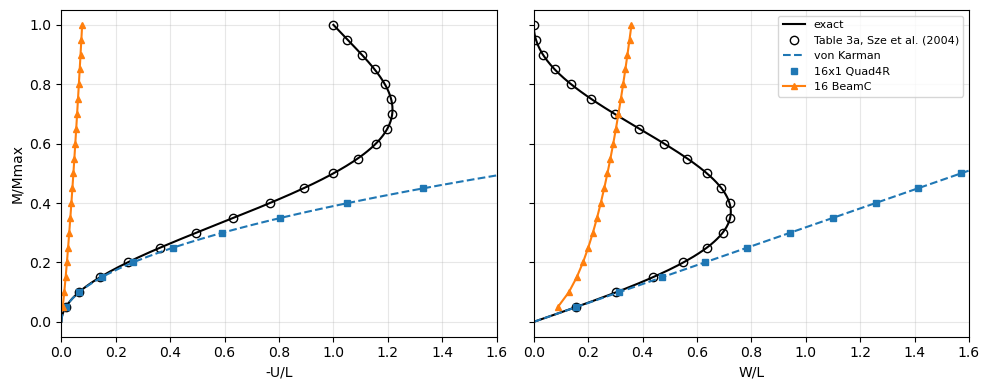

In [3]:
mb, Ub, Wb = run_cantilever_end_moment('BeamC', 16, inc=0.05)
mm = np.linspace(0, 1, 201)
Ue, We = elastica_tip(mm)
Uv, Wv = von_karman_tip(mm)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, label, exact, vk, quad, beam, table in [
        (axes[0], '-U/L', Ue, Uv, U, Ub, TABLE_3A_EXACT[:, 1]/L),
        (axes[1], 'W/L', We, Wv, W, Wb, TABLE_3A_EXACT[:, 2]/L)]:
    ax.plot(exact, mm, 'k-', lw=1.5, label='exact')
    ax.plot(table, TABLE_3A_EXACT[:, 0], 'ko', mfc='none',
            label='Table 3a, Sze et al. (2004)')
    ax.plot(vk, mm, 'C0--', lw=1.5, label='von Karman')
    ax.plot(quad, m, 'C0s', ms=5, label='16x1 Quad4R')
    ax.plot(beam, mb, 'C1^-', ms=5, label='16 BeamC')
    ax.set_xlabel(label)
    ax.set_xlim(0, 1.6)
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('M/Mmax')
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

The deformed cantilever at $M = 0.1 M_{max}$, $0.2 M_{max}$ and
$0.35 M_{max}$, the last one the first configuration of Fig. 3c of Sze et al.
(2004): the exact circular arcs and the edge $y = 0$ of the `Quad4R` strip,
both without amplification.

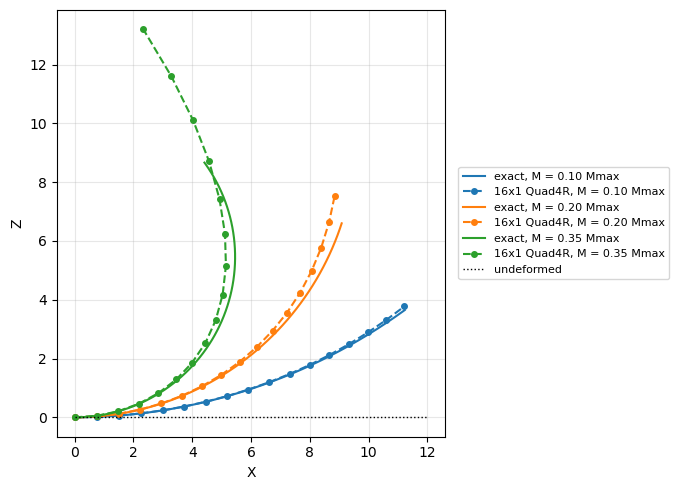

In [4]:
model, bu, tip_deflections, Mmax = cantilever_end_moment('Quad4R', 16)
an = model.analysis(bu, NL_method='NR', initialInc=0.05, maxInc=0.05)
increments, cs = an.static(NLgeom=True, silent=True)
x = model.x.reshape(-1, 3)
edge = np.isclose(x[:, 1], 0.)
s = np.linspace(0, L, 200)
fig, ax = plt.subplots(figsize=(8, 5))
for k, (frac, color) in enumerate([(0.1, 'C0'), (0.2, 'C1'), (0.35, 'C2')]):
    i = int(np.argmin(np.abs(np.array(increments) - frac)))
    u = cs[i].reshape(-1, 6)
    radius = L/(2*np.pi*frac)
    ax.plot(radius*np.sin(s/radius), radius*(1 - np.cos(s/radius)), '-',
            color=color, lw=1.5, label='exact, M = %.2f Mmax' % frac)
    ax.plot(x[edge, 0] + u[edge, 0], x[edge, 2] + u[edge, 2], 'o--',
            color=color, ms=4, label='16x1 Quad4R, M = %.2f Mmax' % frac)
ax.plot([0, L], [0, 0], 'k:', lw=1, label='undeformed')
ax.set_aspect('equal')
ax.set_xlabel('X')
ax.set_ylabel('Z')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

The beam elements `BeamC` and `BeamLR` interpolate the axial displacement
linearly and integrate the von Karman axial strain with Gauss points along
the element, where $w_{,x}^2$ is not constant: the axial strain cannot vanish
in the element and the cantilever is too stiff (membrane locking). The
stiffening grows with the moment and decreases with the number of elements;
at $M = 0.05 M_{max}$:

In [5]:
print('%-7s %9s %10s %12s %10s' % ('element', 'elements', 'W_tip',
                                   'von Karman', 'error %'))
for name in ['BeamC', 'BeamLR']:
    for n in [16, 64, 256]:
        mi, Ui, Wi = run_cantilever_end_moment(name, n, inc=0.25, m_max=0.05)
        Wv = von_karman_tip(mi[-1])[1]
        print('%-7s %9d %10.4f %12.4f %10.2f'
              % (name, n, L*Wi[-1], L*Wv, 100*(Wi[-1]/Wv - 1)))
print('Table 3a (exact) at M/Mmax = 0.05: W_tip %.3f' % TABLE_3A_EXACT[0, 2])

element  elements      W_tip   von Karman    error %
BeamC          16     1.0636       1.8850     -43.57
BeamC          64     1.6477       1.8850     -12.59


BeamC         256     1.8621       1.8850      -1.21
BeamLR         16     1.0637       1.8850     -43.57
BeamLR         64     1.6477       1.8850     -12.59


BeamLR        256     1.8621       1.8850      -1.21
Table 3a (exact) at M/Mmax = 0.05: W_tip 1.870


Hinged cylindrical roof, 12.7 thick
---

Fig. 9a of Sze et al. (2004): cylindrical roof of radius $R = 2540$, length
$2L$ with $L = 254$ along the axis, opening $2\theta$ with
$\theta = 0.1$ rad, thickness $h = 12.7$, $E = 3102.75$, $\nu = 0.3$,
central point load $P$ with $P_{max} = 3000$. The straight edges are hinged,
with all the translations restrained, the curved edges are free. One quarter
is modelled, with symmetry conditions on the planes through the centre C, as
in Sze et al. (2004), who used $16 \times 16$ S4R elements and Riks' method
(Table 9a).

Here one quarter is meshed with $16 \times 16$ flat `Quad4R` elements and the
path is traced with Crisfield's arc-length method up to $1.2 P_{max}$, with
the arc-length increment of `initialInc = maxInc = 0.05`. The load factor
decreases past the limit points, where the tangent stiffness matrix is
singular, which the Newton-Raphson method cannot pass.

In [6]:
P16, W16 = run_hinged_roof(n=16, NL_method='arc_length_crisfield')
P_riks, W_riks = run_hinged_roof(n=16, NL_method='arc_length_riks')
P_nr, W_nr = run_hinged_roof(n=16, NL_method='NR', load_factor=1.)
print("Crisfield's arc-length method: %d increments, P/Pmax %.3f at -W_C %.3f"
      % (len(P16) - 1, P16[-1], W16[-1]))
print("Riks' arc-length method: %d increments, P/Pmax %.3f at -W_C %.3f"
      % (len(P_riks) - 1, P_riks[-1], W_riks[-1]))
print('Newton-Raphson: %d increments, stops at P/Pmax %.4f, -W_C %.3f'
      % (len(P_nr) - 1, P_nr[-1], W_nr[-1]))

P_calc = compare_with_table_9a(P16, W16)
P_riks_calc = compare_with_table_9a(P_riks, W_riks)
print()
print('%8s %10s %10s %10s %10s' % ('-W_C', 'Table 9a', 'pyfe3d', 'diff',
                                   'diff %'))
for (Pr, Wr), Pc in zip(TABLE_9A, P_calc):
    print('%8.3f %10.4f %10.4f %+10.4f %+10.2f'
          % (Wr, Pr, Pc, Pc - Pr, 100*(Pc - Pr)/Pr))
print()
(Pa, Wa), (Pb, Wb) = limit_points(P16, W16, 15.)
(Pa_r, Wa_r), (Pb_r, Wb_r) = limit_points(TABLE_9A[:, 0], TABLE_9A[:, 1], 15.)
print('%-18s %16s %16s' % ('', 'Table 9a', 'pyfe3d'))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('upper limit point', Pa_r, Wa_r, Pa, Wa, 100*(Pa/Pa_r - 1)))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('lower limit point', Pb_r, Wb_r, Pb, Wb, 100*(Pb/Pb_r - 1)))
print()
print("check: Riks' and Crisfield's methods, max difference of P/Pmax at the "
      "deflections of Table 9a %.1e" % np.abs(P_riks_calc - P_calc).max())

Crisfield's arc-length method: 83 increments, P/Pmax 1.200 at -W_C 30.055
Riks' arc-length method: 83 increments, P/Pmax 1.200 at -W_C 30.055
Newton-Raphson: 18 increments, stops at P/Pmax 0.7422, -W_C 10.721

    -W_C   Table 9a     pyfe3d       diff     diff %
   0.693     0.0877     0.0882    +0.0005      +0.60
   1.638     0.1980     0.1995    +0.0015      +0.74
   3.087     0.3473     0.3495    +0.0022      +0.63
   4.477     0.4686     0.4711    +0.0025      +0.52
   5.802     0.5647     0.5671    +0.0024      +0.42
   7.057     0.6381     0.6396    +0.0015      +0.24
   8.237     0.6908     0.6918    +0.0010      +0.14
   9.339     0.7246     0.7245    -0.0001      -0.01
  10.358     0.7412     0.7402    -0.0010      -0.13
  11.293     0.7421     0.7401    -0.0020      -0.27
  12.141     0.7286     0.7256    -0.0030      -0.41
  12.903     0.7023     0.6988    -0.0035      -0.49
  13.583     0.6649     0.6606    -0.0043      -0.65
  14.188     0.6182     0.6138    -0.0044      -

The pyfe3d values are interpolated linearly along the computed path at the
deflections of Table 9a, and the limit points of Table 9a are its largest and
smallest tabulated loads (the table samples the path, the limit points may
lie between its points). Both arc-length methods trace the same path, and
the Newton-Raphson method stops at the upper limit point.

The upper limit load agrees with Table 9a within 0.1 %, and the path within
0.01 $P_{max}$, 0.6 % at its first point; the lower limit load is 2.6 %
below Table 9a, and moves away from it with the mesh, as with `Tria3DSG`,
Table 9a being itself a $16 \times 16$ S4R result, see
`test_hinged_roof_thick`. Up to version 0.11, before the transverse shear of
Belytschko and Leviathan (1994) that `Quad4R` uses since 0.12.0, pyfe3d was
about 7 % stiffer at the start of the path, see the
[last section](#Sensitivity-to-the-stabilisation-of-the-transverse-shear-of-Quad4R).
The mesh convergence of the pyfe3d path is shown below, comparing
$8 \times 8$, $16 \times 16$ and $32 \times 32$ meshes, the last one with a
larger arc-length increment.

 8x8  Quad4R: limit loads 0.7438, 0.1725; P/Pmax at -W_C = 0.693: 0.0904 (Table 9a 0.0877)
16x16 Quad4R: limit loads 0.7423, 0.1685; P/Pmax at -W_C = 0.693: 0.0882 (Table 9a 0.0877)
32x32 Quad4R: limit loads 0.7406, 0.1670; P/Pmax at -W_C = 0.693: 0.0866 (Table 9a 0.0877)


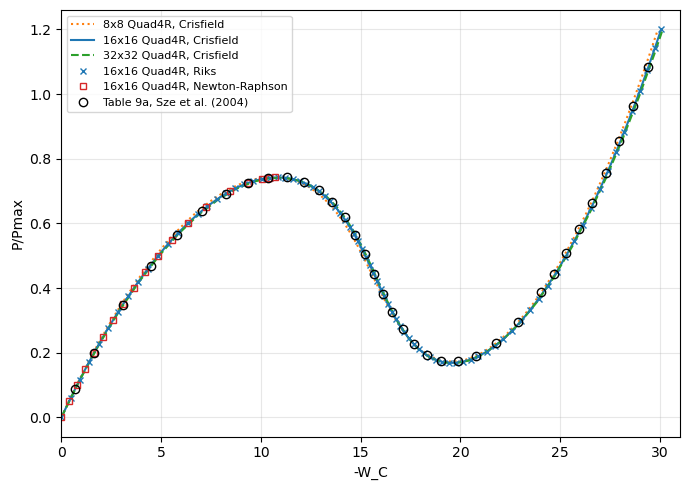

In [7]:
P8, W8 = run_hinged_roof(n=8)
P32, W32 = run_hinged_roof(n=32, initialInc=0.1, maxInc=0.1)
for n, (P, W) in [(8, (P8, W8)), (16, (P16, W16)), (32, (P32, W32))]:
    (Pa, Wa), (Pb, Wb) = limit_points(P, W, 15.)
    Pc = compare_with_table_9a(P, W)
    print('%2dx%-2d Quad4R: limit loads %.4f, %.4f; P/Pmax at -W_C = %.3f: '
          '%.4f (Table 9a %.4f)' % (n, n, Pa, Pb, TABLE_9A[0, 1], Pc[0],
                                    TABLE_9A[0, 0]))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(W8, P8, 'C1:', lw=1.5, label='8x8 Quad4R, Crisfield')
ax.plot(W16, P16, 'C0-', lw=1.5, label='16x16 Quad4R, Crisfield')
ax.plot(W32, P32, 'C2--', lw=1.5, label='32x32 Quad4R, Crisfield')
ax.plot(W_riks, P_riks, 'C0x', ms=5, label='16x16 Quad4R, Riks')
ax.plot(W_nr, P_nr, 'C3s', ms=5, mfc='none', label='16x16 Quad4R, Newton-Raphson')
ax.plot(TABLE_9A[:, 1], TABLE_9A[:, 0], 'ko', mfc='none',
        label='Table 9a, Sze et al. (2004)')
ax.set_xlabel('-W_C')
ax.set_ylabel('P/Pmax')
ax.set_xlim(0, 31)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

Hinged cylindrical roof, 6.35 thick
---

The same roof with half the thickness, $h = 6.35$, Table 9d of Sze et al.
(2004), computed with $24 \times 24$ S4R elements on one quarter. Past the
upper limit point the load becomes negative and the path turns back in the
deflection (snap-back) twice before stiffening. One quarter with
$24 \times 24$ `Quad4R` elements, Crisfield's arc-length method up to
$1.1 P_{max}$ with `initialInc = maxInc = 0.02`.

Crisfield's arc-length method: 116 increments, P/Pmax 1.100 at -W_C 38.872
turning points of -W_C (snap-back): P/Pmax 0.0116 at -W_C 17.072, P/Pmax -0.1117 at -W_C 14.589

                           Table 9d           pyfe3d
upper limit point   0.1953 at 12.89  0.1953 at 13.29  -0.02 %
lower limit point  -0.1288 at 15.78 -0.1294 at 16.23  +0.45 %


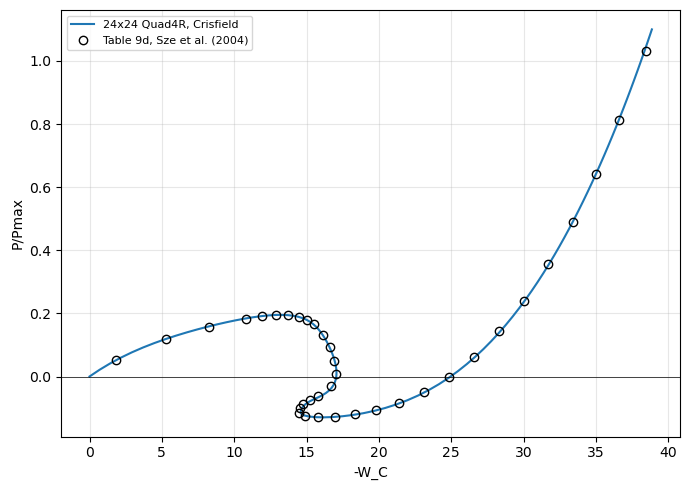

In [8]:
P, W = run_hinged_roof(n=24, h=6.35, load_factor=1.1, initialInc=0.02,
                       maxInc=0.02)
print("Crisfield's arc-length method: %d increments, P/Pmax %.3f at -W_C %.3f"
      % (len(P) - 1, P[-1], W[-1]))
dW = np.diff(W)
turns = np.flatnonzero(np.sign(dW[1:]) != np.sign(dW[:-1])) + 1
print('turning points of -W_C (snap-back): %s' % ', '.join(
    'P/Pmax %.4f at -W_C %.3f' % (P[i], W[i]) for i in turns))
(Pa, Wa), _ = limit_points(P, W, 13.5)
(Pa_r, Wa_r), _ = limit_points(TABLE_9D[:, 0], TABLE_9D[:, 1], 13.5)
i_min, i_min_r = np.argmin(P), np.argmin(TABLE_9D[:, 0])
print()
print('%-18s %16s %16s' % ('', 'Table 9d', 'pyfe3d'))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('upper limit point', Pa_r, Wa_r, Pa, Wa, 100*(Pa/Pa_r - 1)))
print('%-18s %7.4f at %5.2f %7.4f at %5.2f %+6.2f %%'
      % ('lower limit point', TABLE_9D[i_min_r, 0], TABLE_9D[i_min_r, 1],
         P[i_min], W[i_min], 100*(P[i_min]/TABLE_9D[i_min_r, 0] - 1)))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(W, P, 'C0-', lw=1.5, label='24x24 Quad4R, Crisfield')
ax.plot(TABLE_9D[:, 1], TABLE_9D[:, 0], 'ko', mfc='none',
        label='Table 9d, Sze et al. (2004)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('-W_C')
ax.set_ylabel('P/Pmax')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

The upper limit load agrees with the largest load of Table 9d within 0.1 %
and the lower limit load, negative, with the smallest load of Table 9d
within 0.5 %, 0.0006 $P_{max}$; the convergence of both with the mesh is in
`test_hinged_roof_thin_snap_back`. Up to version 0.11 the lower limit load
was 0.015 $P_{max}$ lower, 11.8 %, whatever the mesh.

Sensitivity to the stabilisation of the transverse shear of Quad4R
---

`Quad4R` integrates its stiffness with one point at the centroid. Since
version 0.12.0 its transverse shear is that of Belytschko, T. and
Leviathan, I., Physical stabilization of the 4-node shell element with one
point quadrature, *Computer Methods in Applied Mechanics and Engineering*,
113(3-4), 321-350, 1994,
[doi:10.1016/0045-7825(94)90052-3](https://doi.org/10.1016/0045-7825(94)90052-3):
the assumed shear strains of Dvorkin and Bathe, whose constant part is
integrated at the centroid and whose nonconstant part gives a stabilisation
without parameter, which controls the hourglass mode of $w$; `hgfactor_w`
multiplies that stabilisation, `1` by default, see the Notes of
`pyfe3d.quad4r`. A uniform twist has no assumed shear strain, so the
stabilisation leaves it free, which the constant-twist patch test checks
(`test_constant_twist_patch_test` in
`tests/test_quad4r_hourglass_control.py`). Up to version 0.11 the
hourglass mode of $w$ had the artificial stiffness of Brockman, R. A.,
Dynamics of the bilinear Mindlin plate element, *International Journal for
Numerical Methods in Engineering*, 24(12), 2343-2356, 1987,
[doi:10.1002/nme.1620241208](https://doi.org/10.1002/nme.1620241208),
$0.1 f_w E h^3/(1 + 1/A)$, which added 73 to 78 % to the energy of a
uniform twist of this roof whatever the mesh, a failure of that patch test.
The values of `hgfactor_w` below measure the sensitivity of this problem
only: none of them is a recommendation.

Two references without hourglass control are used:

- `Tria3DSG`, with the same meshes split into two triangles per
  quadrilateral;
- the linear shallow-shell (Donnell-Marguerre) Kirchhoff solution of
  `ritz_roof_WC`, a Ritz method with the Legendre-based functions of
  Castro, S. G. P. and Donadon, M. V., *Composite Structures*, 160,
  232-247, 2017,
  [doi:10.1016/j.compstruct.2016.10.026](https://doi.org/10.1016/j.compstruct.2016.10.026),
  `m` functions per direction for each of $u$, $v$ and $w$. It has no
  transverse shear deformation, so the finite elements are compared with it
  with their transverse shear stiffnesses $A_{44}$, $A_{45}$ and $A_{55}$
  multiplied by 100 (`shear_factor=100.` of `hinged_roof`).

The linear deflection $-W_C$ of the 12.7 thick roof under $P_{max}$:

In [9]:
HGFACTORS = [1., 0.1, 0.03, 0.01, 0.002, 0.0002]
MESHES = [16, 32, 64]
W_ritz = {m: ritz_roof_WC(m) for m in (20, 30)}
print('shallow-shell Kirchhoff Ritz solution: -W_C %.4f (m = 20), %.4f '
      '(m = 30)' % (W_ritz[20], W_ritz[30]))
rows = [('Tria3DSG', dict(element='Tria3DSG'))] + [
    ('Quad4R, hgfactor_w = %g' % hg, dict(hgfactor_w=hg)) for hg in HGFACTORS]
for shear_factor, ref_name in [(1., 'Tria3DSG'), (100., 'Ritz')]:
    W_lin = {name: [linear_roof_WC(n, shear_factor=shear_factor, **kw)
                    for n in MESHES] for name, kw in rows}
    ref = (W_lin['Tria3DSG'][-1] if ref_name == 'Tria3DSG'
           else W_ritz[30])
    print()
    print('linear -W_C under P_max, h = 12.7, transverse shear stiffness '
          'x%g' % shear_factor)
    print('%-28s' % '' + ''.join('%9s' % ('%dx%d' % (n, n)) for n in MESHES)
          + '   64x64 vs %s' % ref_name)
    for name, _ in rows:
        Wn = W_lin[name]
        print('%-28s' % name + ''.join('%9.4f' % Wi for Wi in Wn)
              + '   %+8.2f %%' % (100*(Wn[-1]/ref - 1)))

shallow-shell Kirchhoff Ritz solution: -W_C 7.4798 (m = 20), 7.4801 (m = 30)



linear -W_C under P_max, h = 12.7, transverse shear stiffness x1
                                16x16    32x32    64x64   64x64 vs Tria3DSG
Tria3DSG                       7.5480   7.6295   7.6733      +0.00 %
Quad4R, hgfactor_w = 1         7.5668   7.6490   7.6935      +0.26 %
Quad4R, hgfactor_w = 0.1       7.6142   7.6942   7.7376      +0.84 %
Quad4R, hgfactor_w = 0.03      7.6376   7.7171   7.7604      +1.13 %
Quad4R, hgfactor_w = 0.01      7.6585   7.7379   7.7811      +1.40 %
Quad4R, hgfactor_w = 0.002     7.6862   7.7682   7.8116      +1.80 %
Quad4R, hgfactor_w = 0.0002    7.7038   7.8018   7.8538      +2.35 %



linear -W_C under P_max, h = 12.7, transverse shear stiffness x100
                                16x16    32x32    64x64   64x64 vs Ritz
Tria3DSG                       7.3996   7.4626   7.4795      -0.01 %
Quad4R, hgfactor_w = 1         7.4078   7.4614   7.4789      -0.02 %
Quad4R, hgfactor_w = 0.1       7.4085   7.4622   7.4799      -0.00 %
Quad4R, hgfactor_w = 0.03      7.4090   7.4628   7.4804      +0.00 %
Quad4R, hgfactor_w = 0.01      7.4095   7.4632   7.4807      +0.01 %
Quad4R, hgfactor_w = 0.002     7.4102   7.4637   7.4810      +0.01 %
Quad4R, hgfactor_w = 0.0002    7.4106   7.4641   7.4814      +0.02 %


With the actual transverse shear stiffness the default `Quad4R` meshes are
0.25 to 0.26 % more flexible than the `Tria3DSG` meshes of the same size,
and decreasing `hgfactor_w` increases $-W_C$ monotonically, by 2.1 % from 1
to 0.0002 on the $64 \times 64$ mesh; `Tria3DSG` still grows with the mesh,
by 1.1 % and 0.6 % for each refinement, so that this comparison has no
converged reference.

With the transverse shear stiffnesses multiplied by 100 the comparison has
one: the Ritz solution converges to $-W_C = 7.480$, and the $64 \times 64$
meshes of `Tria3DSG` and of `Quad4R` with every value of `hgfactor_w`
agree with it within 0.02 %. Up to version 0.11 the default `Quad4R` mesh
was 6.0 % stiffer than the Ritz solution and 6.6 % stiffer than
`Tria3DSG`.

The limit loads of the non-linear paths, with $16 \times 16$ meshes, the
arc-length increments of `test_hinged_roof_thick` (0.05) for both
thicknesses and the load at the first point of Tables 9a and 9d,
interpolated along the rising part of the path:

h = 12.7, 16x16, P/Pmax: upper and lower limit loads, load at the first point of Table 9a
                                 upper     lower     first
Table 9a                        0.7421    0.1729    0.0877
Quad4R, hgfactor_w = 1          0.7423    0.1685    0.0882
Quad4R, hgfactor_w = 0.1        0.7422    0.1683    0.0877
Quad4R, hgfactor_w = 0.03       0.7422    0.1682    0.0875
Quad4R, hgfactor_w = 0.01       0.7422    0.1682    0.0872
Quad4R, hgfactor_w = 0.002      0.7422    0.1682    0.0869
Quad4R, hgfactor_w = 0.0002     0.7422    0.1682    0.0868
Tria3DSG                        0.7420    0.1679    0.0884

h = 6.35, 16x16, P/Pmax: upper and lower limit loads, load at the first point of Table 9d
                                 upper     lower     first
Table 9d                        0.1953   -0.1288    0.0517
Quad4R, hgfactor_w = 1          0.1957   -0.1296    0.0524
Quad4R, hgfactor_w = 0.1        0.1956   -0.1294    0.0523
Quad4R, hgfactor_w = 0.03       0.1956   -0.1293    

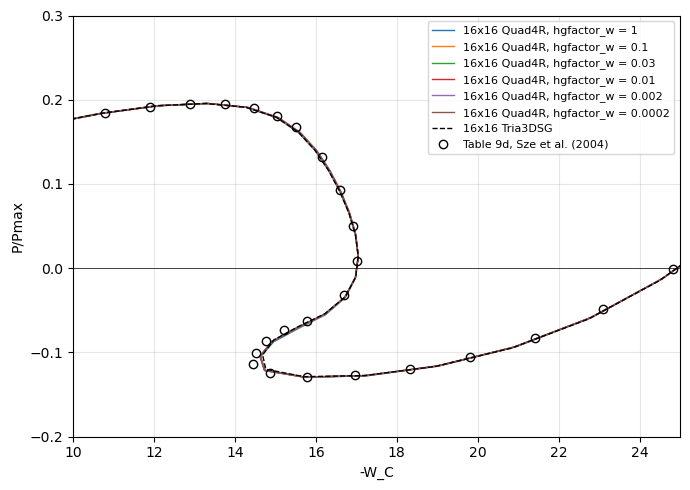

In [10]:
cases = [('Quad4R, hgfactor_w = %g' % hg, dict(hgfactor_w=hg))
         for hg in HGFACTORS] + [('Tria3DSG', dict(element='Tria3DSG'))]
paths_thick, paths_thin = {}, {}
for name, kw in cases:
    if kw.get('hgfactor_w') == 1.:
        # NOTE the path of the 12.7 thick roof with the default, see above
        paths_thick[name] = (P16, W16)
    else:
        paths_thick[name] = run_hinged_roof(n=16, **kw)
    paths_thin[name] = run_hinged_roof(n=16, h=6.35, load_factor=1.1, **kw)


def first_point(P, W, table):
    # NOTE -W_C increases monotonically up to the upper limit point
    rising = W < 10.
    return np.interp(table[0, 1], W[rising], P[rising])


(Pa_r, _), (Pb_r, _) = limit_points(TABLE_9A[:, 0], TABLE_9A[:, 1], 15.)
print('h = 12.7, 16x16, P/Pmax: upper and lower limit loads, load at the '
      'first point of Table 9a')
print('%-28s %9s %9s %9s' % ('', 'upper', 'lower', 'first'))
print('%-28s %9.4f %9.4f %9.4f' % ('Table 9a', Pa_r, Pb_r, TABLE_9A[0, 0]))
for name, (P_, W_) in paths_thick.items():
    (Pa, _), (Pb, _) = limit_points(P_, W_, 15.)
    print('%-28s %9.4f %9.4f %9.4f' % (name, Pa, Pb,
                                       first_point(P_, W_, TABLE_9A)))
(Pa_r, _), _ = limit_points(TABLE_9D[:, 0], TABLE_9D[:, 1], 13.5)
print()
print('h = 6.35, 16x16, P/Pmax: upper and lower limit loads, load at the '
      'first point of Table 9d')
print('%-28s %9s %9s %9s' % ('', 'upper', 'lower', 'first'))
print('%-28s %9.4f %9.4f %9.4f' % ('Table 9d', Pa_r, TABLE_9D[:, 0].min(),
                                   TABLE_9D[0, 0]))
for name, (P_, W_) in paths_thin.items():
    (Pa, _), _ = limit_points(P_, W_, 13.5)
    print('%-28s %9.4f %9.4f %9.4f' % (name, Pa, P_.min(),
                                       first_point(P_, W_, TABLE_9D)))

fig, ax = plt.subplots(figsize=(7, 5))
for (name, (P_, W_)), style in zip(paths_thin.items(),
                                   ['C0-', 'C1-', 'C2-', 'C3-', 'C4-', 'C5-',
                                    'k--']):
    ax.plot(W_, P_, style, lw=1., label='16x16 ' + name)
ax.plot(TABLE_9D[:, 1], TABLE_9D[:, 0], 'ko', mfc='none',
        label='Table 9d, Sze et al. (2004)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('-W_C')
ax.set_ylabel('P/Pmax')
ax.set_xlim(10, 25)
ax.set_ylim(-0.2, 0.3)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

With the default the load at the first point of the tables is 0.6 %
($h = 12.7$) and 1.4 % ($h = 6.35$) above them, and the reduced values of
`hgfactor_w` and `Tria3DSG` are within 1.6 % of the default. The upper limit
loads agree within 0.2 % with the tables for all the values of
`hgfactor_w`. The lower limit loads of $h = 12.7$ are 2.5 to 2.9 % below
Table 9a for all of them and for `Tria3DSG`; those of $h = 6.35$ are
within 0.0008 $P_{max}$ of Table 9d. Up to version 0.11 the default was 7 %
and 8 % stiffer at the first point, and its lower limit load of
$h = 6.35$ was 0.015 $P_{max}$ below Table 9d.

With the $24 \times 24$ mesh and the arc-length increment of 0.02 used
above for Table 9d, `hgfactor_w = 0.002` gives, after the upper limit
point, the path of Table 9d, as the default does:

In [11]:
P24_002, W24_002 = run_hinged_roof(n=24, h=6.35, load_factor=1.1,
                                   initialInc=0.02, maxInc=0.02,
                                   hgfactor_w=0.002)
(Pa, _), _ = limit_points(P24_002, W24_002, 13.5)
print('24x24 Quad4R, hgfactor_w = 0.002: upper and lower limit loads %.4f, '
      '%.4f; Table 9d: %.4f, %.4f' % (Pa, P24_002.min(), Pa_r,
                                      TABLE_9D[:, 0].min()))
for name, (P_, W_) in [('hgfactor_w = 1, above', (P, W)),
                       ('hgfactor_w = 0.002', (P24_002, W24_002)),
                       ('Table 9d', (TABLE_9D[:, 0], TABLE_9D[:, 1]))]:
    dW = np.diff(W_)
    turns = np.flatnonzero(np.sign(dW[1:]) != np.sign(dW[:-1])) + 1
    print('%-22s turning points of -W_C: %s' % (name, ', '.join(
        'P/Pmax %.4f at -W_C %.3f' % (P_[i], W_[i]) for i in turns)))

24x24 Quad4R, hgfactor_w = 0.002: upper and lower limit loads 0.1952, -0.1291; Table 9d: 0.1953, -0.1288
hgfactor_w = 1, above  turning points of -W_C: P/Pmax 0.0116 at -W_C 17.072, P/Pmax -0.1117 at -W_C 14.589
hgfactor_w = 0.002     turning points of -W_C: P/Pmax 0.0116 at -W_C 17.074, P/Pmax -0.1111 at -W_C 14.579
Table 9d               turning points of -W_C: P/Pmax 0.0083 at -W_C 17.008, P/Pmax -0.1142 at -W_C 14.451


Its lower limit load is within 0.0003 $P_{max}$ of the smallest load of
Table 9d, and the path turns back in $-W_C$ at 0.0116 and -0.1111
$P_{max}$, against 0.0083 and -0.1142 $P_{max}$ in Table 9d and 0.0116 and
-0.1117 $P_{max}$ with the default; up to version 0.11 the default turned
back at -0.0139 and -0.1340 $P_{max}$.

The stabilisation of the transverse shear of `Quad4R` therefore leaves
the linear response, the start of the non-linear paths and the lower limit
load of the thinner roof close to the references, and close to the
results with much smaller values of `hgfactor_w`; the lower limit load of
the thinner roof converges to Table 9d with the mesh, see
`test_hinged_roof_thin_snap_back` and
`test_hinged_roof_thin_lower_limit_load`. The assertions of the linear
trend are in `test_hinged_roof_hourglass_sensitivity`.

Williams' toggle frame
---

The toggle frame of Williams, F. W., An approach to the non-linear behaviour
of the members of a rigid jointed plane framework with finite deflections,
*The Quarterly Journal of Mechanics and Applied Mathematics*, 17(4),
451-469, 1964,
[doi:10.1093/qjmam/17.4.451](https://doi.org/10.1093/qjmam/17.4.451), as
reproduced in Fig. 7 of Karamanlidis, D., Honecker, A. and Knothe, K., Large
deflection finite element analysis of pre- and postcritical response of thin
elastic frames, in: Wunderlich, W., Stein, E. and Bathe, K.-J. (eds.),
*Nonlinear Finite Element Analysis in Structural Mechanics*, Springer,
Berlin, Heidelberg, 217-235, 1981,
[doi:10.1007/978-3-642-81589-8_12](https://doi.org/10.1007/978-3-642-81589-8_12)
(p. 228); the paper of Williams was not consulted. Fig. 7 gives: two
straight members of horizontal length 12.943 rising by 0.386 to the apex,
both ends clamped, a central load $P$ at the apex, $E = 10.3 \times 10^6$,
a rectangular cross-section 0.753 wide and 0.243 deep, in the plane of the
frame; it states no units. The reference is the load-deflection curve of
the "present analysis" of Fig. 7, the mixed-hybrid beam elements of
Karamanlidis et al., which agrees with the points of Wood and Zienkiewicz
plotted in the same figure, $w$ being the deflection of the apex.

The curve below was digitised from a scan of the printed figure, at the
square markers of the curve, after fitting the grid lines, whose positions
the fit reproduces within 0.23 in $P$ and 0.0013 in $w$. The line is about
0.3 thick in $P$ and the common origin of the curves is read at
$w = 0.005$, $P = 0.3$: the readings are uncertain by about $\pm 0.3$ in
$P$ and $\pm 0.005$ in $w$, and the deflections of the limit points, on flat
parts of the curve, by about $\pm 0.02$. The limit loads read from the line
are $P = 34.4$ at $w \approx 0.24$ and $P = 32.2$ at $w \approx 0.40$.

Each member is modelled with `BeamC` elements in the $XZ$ plane, with the
out-of-plane displacement and the rotations about $X$ and $Z$ restrained;
Fig. 7 gives no Poisson's ratio, $\nu = 0.3$ is used for the transverse
shear modulus (with $\nu = 0$ or $0.5$ the limit loads of 16 elements per
member change by less than 0.01). The reference load is $P = 70$, reached at
the load factor 1.0 after the snap-through, with arc-length increments of
`initialInc = maxInc = 0.02`.

arc_length_riks       16 BeamC/member: 129 increments, P 70.00 at w 0.6516; upper limit 33.957 at w 0.236, lower limit 31.717 at w 0.389


arc_length_crisfield  16 BeamC/member: 129 increments, P 70.00 at w 0.6516; upper limit 33.957 at w 0.236, lower limit 31.717 at w 0.389
Fig. 7, read: upper limit 34.4 at w ~0.24, lower limit 32.2 at w ~0.40
check: Riks' and Crisfield's methods, max difference of P 7.6e-08


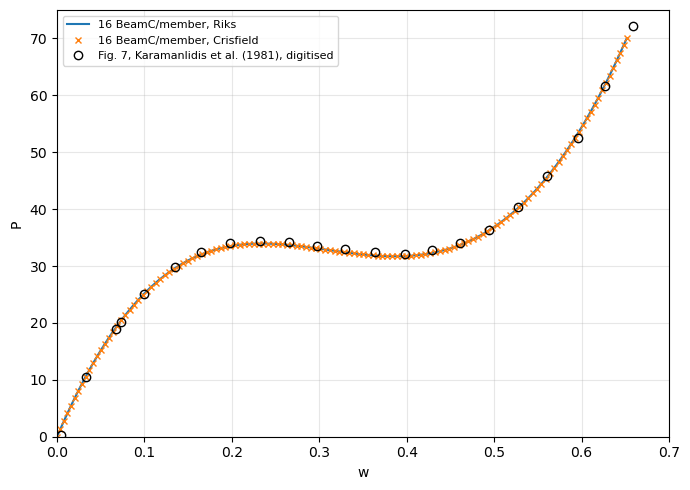

In [12]:
from pyfe3d import BeamC, BeamCData, BeamCProbe, DOF
from pyfe3d.beamprop import BeamProp
from test_solver_nonlinear_static import Model

# NOTE w and P of the curve "present analysis" of Fig. 7 of Karamanlidis et
#      al. (1981), digitised at its markers, and its end point
FIG7_W_P = np.array([
    [0.005, 0.3], [0.033, 10.5], [0.067, 19.0], [0.073, 20.1],
    [0.099, 25.1], [0.135, 29.8], [0.165, 32.4], [0.198, 34.0],
    [0.232, 34.4], [0.265, 34.2], [0.297, 33.5], [0.330, 33.0],
    [0.364, 32.4], [0.398, 32.2], [0.429, 32.8], [0.461, 34.1],
    [0.494, 36.3], [0.527, 40.4], [0.561, 45.8], [0.596, 52.5],
    [0.627, 61.7], [0.659, 72.2]])
# NOTE limit loads read from the line of Fig. 7
FIG7_UPPER, FIG7_LOWER = 34.4, 32.2


def toggle_frame(n_member, P_ref=70., span=12.943, rise=0.386, E=10.3e6,
                 b=0.753, t=0.243, nu=0.3):
    """Williams' toggle frame with n_member BeamC elements per member"""
    prop = BeamProp()
    prop.A = b*t
    prop.E = E
    prop.G = E/2/(1 + nu)
    prop.Iyy = b*t**3/12 # bending in the XZ plane
    prop.Izz = t*b**3/12
    prop.J = b*t**3/3
    num_nodes = 2*n_member + 1
    xs = np.linspace(0, 2*span, num_nodes)
    zs = rise*(1 - np.abs(xs - span)/span)
    x = np.vstack((xs, 0*xs, zs)).T.flatten()
    data, probe = BeamCData(), BeamCProbe()
    elements = []
    for k in range(num_nodes - 1):
        elem = BeamC(probe)
        elem.n1, elem.n2 = k, k + 1
        elem.c1, elem.c2 = DOF*k, DOF*(k + 1)
        elem.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        elem.init_k_KCNL = k*data.KCNL_SPARSE_SIZE
        elem.init_k_KG = k*data.KG_SPARSE_SIZE
        elem.update_rotation_matrix(0., 1., 0., x)
        elem.update_probe_xe(x)
        elements.append(elem)
    N = DOF*num_nodes
    bk = np.zeros(N, dtype=bool)
    # NOTE planar frame: v, rx and rz restrained; both ends clamped
    bk[1::DOF] = bk[3::DOF] = bk[5::DOF] = True
    bk[:DOF] = bk[-DOF:] = True
    fext = np.zeros(N)
    apex = DOF*n_member + 2
    fext[apex] = -P_ref
    return Model(elements, data, prop, x, N, fext), ~bk, apex


def run_toggle_frame(n_member, NL_method, P_ref=70., inc=0.02):
    model, bu, apex = toggle_frame(n_member, P_ref=P_ref)
    an = model.analysis(bu, NL_method=NL_method, initialInc=inc,
                        maxInc=inc, maxArcLength=1e6)
    increments, cs = an.static(NLgeom=True, silent=True)
    P = P_ref*np.r_[0., increments]
    w = -np.r_[0., [c[apex] for c in cs]]
    return P, w


def toggle_limit_points(P, w):
    """First local maximum of P and the next local minimum"""
    dP = np.diff(P)
    i = int(np.flatnonzero(dP < 0)[0])
    j = i + int(np.flatnonzero(dP[i:] > 0)[0])
    return (P[i], w[i]), (P[j], w[j])


paths = {}
for method in ['arc_length_riks', 'arc_length_crisfield']:
    P, w = run_toggle_frame(16, method)
    paths[method] = P, w
    (Pa, wa), (Pb, wb) = toggle_limit_points(P, w)
    print('%-21s 16 BeamC/member: %d increments, P %.2f at w %.4f; upper '
          'limit %.3f at w %.3f, lower limit %.3f at w %.3f'
          % (method, len(P) - 1, P[-1], w[-1], Pa, wa, Pb, wb))
print('Fig. 7, read: upper limit %.1f at w ~0.24, lower limit %.1f at w '
      '~0.40' % (FIG7_UPPER, FIG7_LOWER))
P, w = paths['arc_length_riks']
Pc = paths['arc_length_crisfield'][0]
print("check: Riks' and Crisfield's methods, max difference of P %.1e"
      % np.abs(P - Pc).max())

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(w, P, 'C0-', lw=1.5, label="16 BeamC/member, Riks")
ax.plot(paths['arc_length_crisfield'][1], Pc, 'C1x', ms=4,
        label="16 BeamC/member, Crisfield")
ax.plot(FIG7_W_P[:, 0], FIG7_W_P[:, 1], 'ko', mfc='none',
        label='Fig. 7, Karamanlidis et al. (1981), digitised')
ax.set_xlabel('w')
ax.set_ylabel('P')
ax.set_xlim(0, 0.7)
ax.set_ylim(0, 75)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

Both arc-length methods trace the same path, through the upper limit point,
the snap-through and the lower limit point, to the load factor 1.0. The
limit loads with 8 to 64 elements per member, compared with those read from
Fig. 7:

In [13]:
print('%-14s %16s %16s %9s %9s' % ('BeamC/member', 'upper limit',
                                   'lower limit', 'upper %', 'lower %'))
for n in [8, 16, 32, 64]:
    P_, w_ = (paths['arc_length_riks'] if n == 16
              else run_toggle_frame(n, 'arc_length_riks'))
    (Pa, wa), (Pb, wb) = toggle_limit_points(P_, w_)
    print('%-14d %7.3f at %5.3f %7.3f at %5.3f %+9.2f %+9.2f'
          % (n, Pa, wa, Pb, wb, 100*(Pa/FIG7_UPPER - 1),
             100*(Pb/FIG7_LOWER - 1)))
print('%-14s %7.1f at %5s %7.1f at %5s' % ('Fig. 7', FIG7_UPPER, '~0.24',
                                          FIG7_LOWER, '~0.40'))

BeamC/member        upper limit      lower limit   upper %   lower %


8               34.308 at 0.241  33.007 at 0.367     -0.27     +2.51
16              33.957 at 0.236  31.717 at 0.389     -1.29     -1.50


32              33.871 at 0.231  31.354 at 0.389     -1.54     -2.63


64              33.851 at 0.231  31.260 at 0.394     -1.60     -2.92
Fig. 7            34.4 at ~0.24    32.2 at ~0.40


The limit loads converge with the number of elements, the differences
between successive meshes decreasing about four times at each refinement,
to about 33.85 and 31.26 with 64 elements per member: 1.6 % and 2.9 % below
the values read from Fig. 7, more than the reading uncertainty. Coarse
meshes are too stiff, as in the cantilever above; with 4 elements per member
the path has no limit point at all. The deflections of the limit points
agree with Fig. 7 within the reading uncertainty.

Summary
---

| benchmark | reference | pyfe3d |
|---|---|---|
| cantilever under end moment | Table 3a, exact, rolls up into a circle | `Quad4R`: the von Karman solution, within 1 % of Table 3a at $M = 0.05 M_{max}$, no roll-up; `BeamC`, `BeamLR`: membrane locking, converging to the von Karman solution with the number of elements |
| hinged roof, $h = 12.7$ | Table 9a | `Quad4R` with its default stabilisation: upper limit load within 0.1 %, path within 0.01 $P_{max}$; lower limit load 2.6 % lower, as with `Tria3DSG` |
| hinged roof, $h = 6.35$ | Table 9d | snap-through and snap-back traced; `Quad4R` with its default stabilisation: upper limit load within 0.1 %, lower limit load within 0.5 % |
| Williams' toggle frame | Fig. 7 of Karamanlidis et al. (1981), digitised | `BeamC`, both arc-length methods: the same path, limit loads converging to 1.6 % (upper) and 2.9 % (lower) below those read from the figure |
| sensitivity to `hgfactor_w` | Tables 9a and 9d, `Tria3DSG`, shallow-shell Kirchhoff Ritz solution | the default `Quad4R` is within 0.3 % of `Tria3DSG` in the linear range and converges to the Ritz solution; smaller values change the results by at most 2 % (up to version 0.11 the default was 6 to 7 % stiffer) |

The references of the first four rows are of Sze et al. (2004). The
assertions of their comparisons are in
`tests/test_nonlinear_benchmarks_sze2004.py`; the toggle frame is compared
in this notebook only.